In [1]:
import sys

print("Python version:")
print(sys.version)

print("\nPython environment:")
print(sys.executable)

import geopandas as gpd
import rasterio
import rioxarray
import shapely
import pyproj
import pandas as pd
import numpy as np
import matplotlib
import folium

print("\nGIS packages loaded successfully.")
print("GeoPandas:", gpd.__version__)
print("Rasterio:", rasterio.__version__)
print("Shapely:", shapely.__version__)
print("PyProj:", pyproj.__version__) 

Python version:
3.12.15 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:14:50) [MSC v.1942 64 bit (AMD64)]

Python environment:
C:\Users\Lioness_eni\anaconda3\envs\epe_atlas\python.exe

GIS packages loaded successfully.
GeoPandas: 1.2.0
Rasterio: 1.5.0
Shapely: 2.1.2
PyProj: 3.7.2


In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

print("Ready for spatial analysis.")

Ready for spatial analysis.


In [4]:
from pathlib import Path

project = Path.cwd()

print("Current project folder:")
print(project)

print("\nContents:")
for item in project.iterdir():
    print(item.name)

Current project folder:
C:\Users\Lioness_eni\Epe_Coastal_Atlas

Contents:
.ipynb_checkpoints
01_Epe_Study_Area.ipynb
data
documentation
notebooks
outputs
scripts


In [7]:
import requests

layer_url = "https://services3.arcgis.com/BU6Aadhn6tbBEdyk/ArcGIS/rest/services/GRID3_Nigeria_Local_Government_Area_Boundaries_with_Names/FeatureServer/0"

params = {
    "f": "json"
}

response = requests.get(layer_url, params=params, timeout=60)

print("HTTP status:", response.status_code)

layer_info = response.json()

print("\nLayer name:")
print(layer_info.get("name"))

print("\nGeometry type:")
print(layer_info.get("geometryType"))

print("\nFields:")
for field in layer_info.get("fields", []):
    print(field["name"], "—", field["type"])

HTTP status: 200

Layer name:
None

Geometry type:
None

Fields:


In [8]:
print(layer_info)

{'error': {'code': 400, 'message': '', 'details': ['The requested layer (layerId: 0) was not found.']}}


In [9]:
import requests

service_url = "https://services3.arcgis.com/BU6Aadhn6tbBEdyk/ArcGIS/rest/services/GRID3_Nigeria_Local_Government_Area_Boundaries_with_Names/FeatureServer"

response = requests.get(
    service_url,
    params={"f": "json"},
    timeout=60
)

print("HTTP status:", response.status_code)

service_info = response.json()

print("\nService name:")
print(service_info.get("name"))

print("\nLayers:")
for layer in service_info.get("layers", []):
    print(layer)

HTTP status: 200

Service name:
None

Layers:
{'id': 11, 'name': 'GRID3_NGA_LGA_bounds_names', 'parentLayerId': -1, 'defaultVisibility': True, 'subLayerIds': None, 'minScale': 0, 'maxScale': 0, 'type': 'Feature Layer', 'geometryType': 'esriGeometryPolygon'}


In [10]:
layer_url = (
    "https://services3.arcgis.com/BU6Aadhn6tbBEdyk/"
    "ArcGIS/rest/services/"
    "GRID3_Nigeria_Local_Government_Area_Boundaries_with_Names/"
    "FeatureServer/11"
)

response = requests.get(
    layer_url,
    params={"f": "json"},
    timeout=60
)

print("HTTP status:", response.status_code)

layer_info = response.json()

print("\nLayer name:")
print(layer_info.get("name"))

print("\nGeometry type:")
print(layer_info.get("geometryType"))

print("\nFields:")
for field in layer_info.get("fields", []):
    print(field["name"], "—", field["type"])

HTTP status: 200

Layer name:
GRID3_NGA_LGA_bounds_names

Geometry type:
esriGeometryPolygon

Fields:
FID — esriFieldTypeOID
lga_code — esriFieldTypeString
lga_name — esriFieldTypeString
state_code — esriFieldTypeString
state_name — esriFieldTypeString
Shape_Leng — esriFieldTypeDouble
Shape__Area — esriFieldTypeDouble
Shape__Length — esriFieldTypeDouble


In [11]:
import geopandas as gpd
import requests

layer_url = (
    "https://services3.arcgis.com/BU6Aadhn6tbBEdyk/"
    "ArcGIS/rest/services/"
    "GRID3_Nigeria_Local_Government_Area_Boundaries_with_Names/"
    "FeatureServer/11/query"
)

params = {
    "where": "lga_name = 'Epe'",
    "outFields": "*",
    "returnGeometry": "true",
    "f": "geojson"
}

response = requests.get(
    layer_url,
    params=params,
    timeout=60
)

print("HTTP status:", response.status_code)

response.raise_for_status()

data = response.json()

print("Features returned:", len(data["features"]))

epe = gpd.GeoDataFrame.from_features(
    data["features"],
    crs="EPSG:4326"
)

print("\nEpe boundary:")
print(epe[["lga_code", "lga_name", "state_name"]])

print("\nGeometry:")
print(epe.geometry.geom_type.tolist())

print("\nCRS:")
print(epe.crs)

HTTP status: 200
Features returned: 1

Epe boundary:
  lga_code lga_name state_name
0    25007      Epe      Lagos

Geometry:
['Polygon']

CRS:
EPSG:4326


In [12]:
from pathlib import Path

raw_folder = Path("../data/raw")
raw_folder.mkdir(parents=True, exist_ok=True)

output_file = raw_folder / "epe_lga_boundary.geojson"

epe.to_file(output_file, driver="GeoJSON")

print("Boundary saved to:")
print(output_file.resolve())

Boundary saved to:
C:\Users\Lioness_eni\data\raw\epe_lga_boundary.geojson


In [13]:
import geopandas as gpd
from pathlib import Path

boundary_file = Path("../data/raw/epe_lga_boundary.geojson")

epe_check = gpd.read_file(boundary_file)

print("File loaded successfully.")
print("\nNumber of features:", len(epe_check))
print("\nCRS:", epe_check.crs)
print("\nGeometry type:", epe_check.geometry.geom_type.tolist())

print("\nAttributes:")
print(epe_check[["lga_code", "lga_name", "state_name"]])

File loaded successfully.

Number of features: 1

CRS: EPSG:4326

Geometry type: ['Polygon']

Attributes:
  lga_code lga_name state_name
0    25007      Epe      Lagos


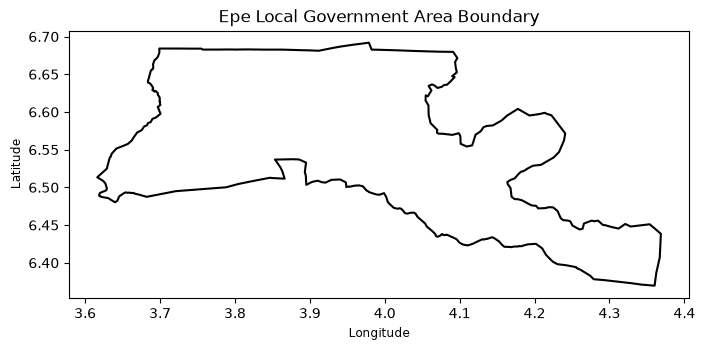

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 8))

epe_check.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=1.5
)

ax.set_title("Epe Local Government Area Boundary")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()

In [15]:
print("Coordinate extent of Epe LGA:")

print("Minimum longitude:", epe_check.total_bounds[0])
print("Minimum latitude:", epe_check.total_bounds[1])
print("Maximum longitude:", epe_check.total_bounds[2])
print("Maximum latitude:", epe_check.total_bounds[3])

Coordinate extent of Epe LGA:
Minimum longitude: 3.61619059382087
Minimum latitude: 6.36961033774696
Maximum longitude: 4.3686295177381
Maximum latitude: 6.69193444571812


In [16]:
epe_utm = epe_check.to_crs("EPSG:32631")

print("Original CRS:")
print(epe_check.crs)

print("\nProjected CRS:")
print(epe_utm.crs)

print("\nArea in square metres:")
print(epe_utm.geometry.area.iloc[0])

print("\nArea in square kilometres:")
print(epe_utm.geometry.area.iloc[0] / 1_000_000)

Original CRS:
EPSG:4326

Projected CRS:
EPSG:32631

Area in square metres:
1314234934.1835103

Area in square kilometres:
1314.2349341835104


In [17]:
processed_folder = Path("../data/processed")
processed_folder.mkdir(parents=True, exist_ok=True)

projected_file = processed_folder / "epe_lga_boundary_utm31n.gpkg"

epe_utm.to_file(
    projected_file,
    layer="epe_lga_boundary",
    driver="GPKG"
)

print("Projected boundary saved to:")
print(projected_file.resolve())

Projected boundary saved to:
C:\Users\Lioness_eni\data\processed\epe_lga_boundary_utm31n.gpkg


In [18]:
import requests

service_url = (
    "https://services3.arcgis.com/BU6Aadhn6tbBEdyk/"
    "ArcGIS/rest/services/"
    "GRID3_Epe_LGA_GIS/FeatureServer"
)

response = requests.get(
    service_url,
    params={"f": "json"},
    timeout=60
)

print("HTTP status:", response.status_code)

service_info = response.json()

print("\nAvailable layers:")

for layer in service_info.get("layers", []):
    print(
        "ID:", layer["id"],
        "| Name:", layer["name"],
        "| Type:", layer["type"]
    )

HTTP status: 200

Available layers:


In [19]:
import requests

service_url = "https://services3.arcgis.com/BU6Aadhn6tbBEdyk/ArcGIS/rest/services/Epe_GIS/FeatureServer"

response = requests.get(
    service_url,
    params={"f": "json"},
    timeout=60
)

print("HTTP status:", response.status_code)

service_info = response.json()

print("\nAvailable layers:")

for layer in service_info.get("layers", []):
    print(
        "ID:", layer["id"],
        "| Name:", layer["name"],
        "| Type:", layer["type"],
        "| Geometry:", layer.get("geometryType")
    )

HTTP status: 200

Available layers:


In [20]:
import geopandas as gpd
import requests

base_url = "https://services8.arcgis.com/oTalEaSXAuyNT7xf/ArcGIS/rest/services/DIGITAL_MAPPING_GROUP_6__MAP_OF_EPE_WFL1/FeatureServer"

def get_layer(layer_id):
    url = f"{base_url}/{layer_id}/query"

    params = {
        "where": "1=1",
        "outFields": "*",
        "returnGeometry": "true",
        "f": "geojson"
    }

    response = requests.get(url, params=params, timeout=60)
    print(f"Layer {layer_id} HTTP status:", response.status_code)

    response.raise_for_status()

    data = response.json()

    return gpd.GeoDataFrame.from_features(
        data["features"],
        crs="EPSG:3857"
    )

# Waterways
waterways = get_layer(8)

# Water bodies
waterbodies = get_layer(13)

print("\nWaterways:", len(waterways))
print("Waterbodies:", len(waterbodies))

print("\nWaterways columns:")
print(waterways.columns.tolist())

print("\nWaterbody columns:")
print(waterbodies.columns.tolist())

Layer 8 HTTP status: 200
Layer 13 HTTP status: 200

Waterways: 17
Waterbodies: 18

Waterways columns:
['geometry', 'FID', 'fclass', 'name', 'length', 'Shape__Length']

Waterbody columns:
['geometry', 'FID', 'fclass', 'name', 'area', 'Shape__Area', 'Shape__Length']


In [21]:
print("WATERWAYS")
print(waterways[["FID", "fclass", "name", "length"]].to_string(index=False))

print("\nWATERBODIES")
print(waterbodies[["FID", "fclass", "name", "area"]].to_string(index=False))

WATERWAYS
 FID fclass           name       length
   1  river      Aye River 11431.012338
   2  river     Osun River  3683.418488
   3  river    Oshun River  8108.846903
   4  river    Oshun River  4244.053044
   5  river    Oshun River  1210.494075
   6  river    Oshun River   241.663727
   7  river    Oshun River    54.870169
   8  river        Sunmoge  8956.775771
   9  river Mosafejo River  1876.681276
  10 stream                 8912.123901
  11 stream                  994.691113
  12 stream                 1399.186699
  13 stream                 4646.332096
  14 stream                 8209.609406
  15 stream                 2047.087602
  16 stream                  288.857549
  17  river     Saga River  3268.587581

WATERBODIES
 FID    fclass         name      area
   1     water                    533
   2     water                    351
   3     water                    535
   4     water                    533
   5 riverbank    Omu creek   2723412
   6 riverbank               

In [22]:
waterways_epe = gpd.clip(waterways, epe_check)
waterbodies_epe = gpd.clip(waterbodies, epe_check)

print("Waterways inside Epe LGA:", len(waterways_epe))
print("Waterbodies inside Epe LGA:", len(waterbodies_epe))

C:\Users\Lioness_eni\AppData\Local\Temp\ipykernel_12696\1031218300.py:1: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: EPSG:3857
Right CRS: EPSG:4326

  waterways_epe = gpd.clip(waterways, epe_check)
C:\Users\Lioness_eni\AppData\Local\Temp\ipykernel_12696\1031218300.py:2: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: EPSG:3857
Right CRS: EPSG:4326

  waterbodies_epe = gpd.clip(waterbodies, epe_check)


Waterways inside Epe LGA: 17
Waterbodies inside Epe LGA: 18


In [23]:
print("\nNamed waterways:")
print(
    waterways_epe[waterways_epe["name"].notna()][["fclass", "name"]]
    .drop_duplicates()
    .to_string(index=False)
)

print("\nNamed waterbodies:")
print(
    waterbodies_epe[waterbodies_epe["name"].notna()][["fclass", "name"]]
    .drop_duplicates()
    .to_string(index=False)
)


Named waterways:
fclass           name
stream               
 river        Sunmoge
 river Mosafejo River
 river    Oshun River
 river     Saga River
 river     Osun River
 river      Aye River

Named waterbodies:
   fclass         name
    water             
riverbank             
  wetland             
    water Lekki Lagoon
    water   Epe Lagoon
riverbank    Omu creek
    water Lagos Lagoon


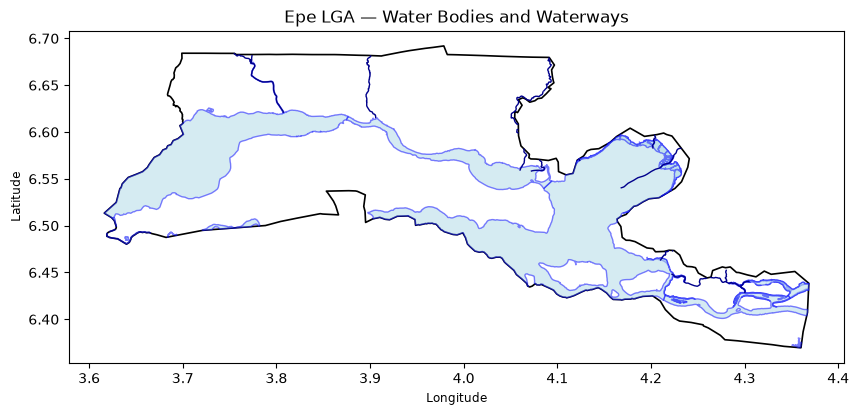

In [24]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))

epe_check.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=1.2
)

waterbodies_epe.plot(
    ax=ax,
    color="lightblue",
    edgecolor="blue",
    alpha=0.5
)

waterways_epe.plot(
    ax=ax,
    color="darkblue",
    linewidth=1
)

ax.set_title("Epe LGA — Water Bodies and Waterways")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()

In [25]:
from pathlib import Path

raw_folder = Path("../data/raw")

waterways_file = raw_folder / "epe_waterways.geojson"
waterbodies_file = raw_folder / "epe_waterbodies.geojson"

waterways_epe.to_file(waterways_file, driver="GeoJSON")
waterbodies_epe.to_file(waterbodies_file, driver="GeoJSON")

print("Saved:")
print(waterways_file.resolve())
print(waterbodies_file.resolve())

Saved:
C:\Users\Lioness_eni\data\raw\epe_waterways.geojson
C:\Users\Lioness_eni\data\raw\epe_waterbodies.geojson


In [29]:
import requests

overpass_url = "https://overpass.kumi.systems/api/interpreter"

response = requests.post(
    overpass_url,
    data={"data": query},
    headers={"User-Agent": "Epe-Coastal-Atlas/1.0"},
    timeout=90
)

print("HTTP status:", response.status_code)

response.raise_for_status()

osm_data = response.json()

print("Features found:", len(osm_data["elements"]))

HTTP status: 500


HTTPError: 500 Server Error: Internal Server Error for url: https://overpass.kumi.systems/api/interpreter

In [30]:
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point

data = [
    {
        "name": "Oluwo Modern Fish Market",
        "category": "Fish Market",
        "lat": 6.582271,
        "lon": 3.990089,
        "osm_id": "node/10164480090",
        "evidence_tier": "Tier 2: Secondary / Mapped",
    },
    {
        "name": "Ebute Oluwo Landing Point",
        "category": "Fish Landing Site",
        "lat": 6.582260,
        "lon": 3.982650,
        "osm_id": "ref_ebute_01",
        "evidence_tier": "Tier 2: Secondary / Field Survey",
    },
    {
        "name": "Epe Marina Waterfront & Jetty",
        "category": "Fishing Jetty / Harbour",
        "lat": 6.579710,
        "lon": 3.980740,
        "osm_id": "ref_marina_01",
        "evidence_tier": "Tier 2: Secondary / Mapped",
    },
    {
        "name": "Ebute Erepoto Landing Site",
        "category": "Fish Landing Site",
        "lat": 6.577180,
        "lon": 3.968540,
        "osm_id": "ref_erepoto_01",
        "evidence_tier": "Tier 2: Secondary / Field Survey",
    },
    {
        "name": "Ebute Berger Landing Site",
        "category": "Fish Landing Site",
        "lat": 6.575986,
        "lon": 3.945330,
        "osm_id": "ref_berger_01",
        "evidence_tier": "Tier 2: Secondary / Field Survey",
    },
    {
        "name": "Shaldag Aquaculture Farm",
        "category": "Aquaculture Facility",
        "lat": 6.593764,
        "lon": 3.939745,
        "osm_id": "way/10150154736",
        "evidence_tier": "Tier 2: Secondary / Mapped",
    },
    {
        "name": "Ketu-Ereyun Aquaculture Farm Estate",
        "category": "Aquaculture Facility",
        "lat": 6.583300,
        "lon": 3.983300,
        "osm_id": "ref_ketuereyun_01",
        "evidence_tier": "Tier 2: Secondary / Authoritative Planned",
    },
    {
        "name": "Ebute Afuye Landing Point",
        "category": "Fishing Activity Location",
        "lat": 6.584000,
        "lon": 3.895000,
        "osm_id": "ref_afuye_01",
        "evidence_tier": "Tier 2: Secondary / Field Survey",
    },
    {
        "name": "Ejinrin Lagoon Waterfront & Jetty",
        "category": "Fishing Jetty / Harbour",
        "lat": 6.602500,
        "lon": 3.874100,
        "osm_id": "ref_ejinrin_01",
        "evidence_tier": "Tier 2: Secondary / Mapped",
    },
]

df = pd.DataFrame(data)
geometry = [Point(xy) for xy in zip(df["lon"], df["lat"])]
gdf = gpd.GeoDataFrame(df, geometry=geometry, crs="EPSG:4326")

# Reproject to project metric standard UTM Zone 31N
gdf_utm = gdf.to_crs("EPSG:32631")

# Export to GeoPackage
gdf_utm.to_file(
    "data/processed/epe_fisheries_aquaculture_utm31n.gpkg",
    layer="fisheries_aquaculture_points",
    driver="GPKG",
)
print(f"Exported {len(gdf_utm)} fisheries features to GPKG.")

Exported 9 fisheries features to GPKG.


In [31]:
import geopandas as gpd

# Load Epe boundary
epe = gpd.read_file(
    "data/processed/epe_lga_boundary_utm31n.gpkg",
    layer="epe_lga_boundary"
)

# Load fisheries/aquaculture points
fisheries = gpd.read_file(
    "data/processed/epe_fisheries_aquaculture_utm31n.gpkg",
    layer="fisheries_aquaculture_points"
)

# Check CRS
print("Epe CRS:", epe.crs)
print("Fisheries CRS:", fisheries.crs)

# Check which points fall inside Epe LGA
fisheries["inside_epe"] = fisheries.geometry.within(
    epe.geometry.iloc[0]
)

print("\nPoints inside Epe:", fisheries["inside_epe"].sum())
print("Points outside Epe:", (~fisheries["inside_epe"]).sum())

# Show the results
print(
    fisheries[
        ["name", "category", "evidence_tier", "inside_epe"]
    ].to_string(index=False)
)

DataSourceError: data/processed/epe_lga_boundary_utm31n.gpkg: No such file or directory

In [32]:
from pathlib import Path

print("Current folder:")
print(Path.cwd())

print("\nProcessed folder contents:")
for item in Path("../data/processed").iterdir():
    print(item)

Current folder:
C:\Users\Lioness_eni\Epe_Coastal_Atlas

Processed folder contents:
..\data\processed\epe_lga_boundary_utm31n.gpkg


In [33]:
import geopandas as gpd

# Load Epe boundary
epe = gpd.read_file(
    "data/processed/epe_lga_boundary_utm31n.gpkg",
    layer="epe_lga_boundary"
)

# Load fisheries/aquaculture points
fisheries = gpd.read_file(
    "data/processed/epe_fisheries_aquaculture_utm31n.gpkg",
    layer="fisheries_aquaculture_points"
)

# Check CRS
print("Epe CRS:", epe.crs)
print("Fisheries CRS:", fisheries.crs)

# Check which points fall inside Epe
fisheries["inside_epe"] = fisheries.geometry.within(
    epe.geometry.iloc[0]
)

print("\nPoints inside Epe:", fisheries["inside_epe"].sum())
print("Points outside Epe:", (~fisheries["inside_epe"]).sum())

print(
    fisheries[
        ["name", "category", "evidence_tier", "inside_epe"]
    ].to_string(index=False)
)

DataSourceError: data/processed/epe_lga_boundary_utm31n.gpkg: No such file or directory

In [34]:
from pathlib import Path

print("Current folder:")
print(Path.cwd())

print("\nProcessed folder contents:")
for item in Path("../data/processed").iterdir():
    print(item)

Current folder:
C:\Users\Lioness_eni\Epe_Coastal_Atlas

Processed folder contents:
..\data\processed\epe_lga_boundary_utm31n.gpkg


In [35]:
import geopandas as gpd

# Load Epe boundary
epe = gpd.read_file(
    "data/processed/epe_lga_boundary_utm31n.gpkg",
    layer="epe_lga_boundary"
)

# Load fisheries/aquaculture points
fisheries = gpd.read_file(
    "data/processed/epe_fisheries_aquaculture_utm31n.gpkg",
    layer="fisheries_aquaculture_points"
)

# Check CRS
print("Epe CRS:", epe.crs)
print("Fisheries CRS:", fisheries.crs)

# Check which points fall inside Epe
fisheries["inside_epe"] = fisheries.geometry.within(
    epe.geometry.iloc[0]
)

print("\nPoints inside Epe:", fisheries["inside_epe"].sum())
print("Points outside Epe:", (~fisheries["inside_epe"]).sum())

print(
    fisheries[
        ["name", "category", "evidence_tier", "inside_epe"]
    ].to_string(index=False)
)

DataSourceError: data/processed/epe_lga_boundary_utm31n.gpkg: No such file or directory

In [36]:
import geopandas as gpd

# Load Epe boundary from the raw GeoJSON
epe = gpd.read_file(
    "data/raw/epe_lga_boundary.geojson"
)

# Load fisheries/aquaculture points
fisheries = gpd.read_file(
    "data/processed/epe_fisheries_aquaculture_utm31n.gpkg",
    layer="fisheries_aquaculture_points"
)

# Put boundary into the same CRS
epe = epe.to_crs("EPSG:32631")

# Check which points fall inside Epe
fisheries["inside_epe"] = fisheries.geometry.within(
    epe.geometry.iloc[0]
)

print("Epe CRS:", epe.crs)
print("Fisheries CRS:", fisheries.crs)

print("\nPoints inside Epe:", fisheries["inside_epe"].sum())
print("Points outside Epe:", (~fisheries["inside_epe"]).sum())

print(
    fisheries[
        ["name", "category", "evidence_tier", "inside_epe"]
    ].to_string(index=False)
)

DataSourceError: data/raw/epe_lga_boundary.geojson: No such file or directory

In [37]:
# Recreate the fisheries points from the data already collected

import geopandas as gpd
import pandas as pd
from shapely.geometry import Point, box

# Fisheries dataset
data = [
    {"name": "Oluwo Modern Fish Market", "category": "Fish Market", "lat": 6.582271, "lon": 3.990089},
    {"name": "Ebute Oluwo Landing Point", "category": "Fish Landing Site", "lat": 6.582260, "lon": 3.982650},
    {"name": "Epe Marina Waterfront & Jetty", "category": "Fishing Jetty / Harbour", "lat": 6.579710, "lon": 3.980740},
    {"name": "Ebute Erepoto Landing Site", "category": "Fish Landing Site", "lat": 6.577180, "lon": 3.968540},
    {"name": "Ebute Berger Landing Site", "category": "Fish Landing Site", "lat": 6.575986, "lon": 3.945330},
    {"name": "Shaldag Aquaculture Farm", "category": "Aquaculture Facility", "lat": 6.593764, "lon": 3.939745},
    {"name": "Ketu-Ereyun Aquaculture Farm Estate", "category": "Aquaculture Facility", "lat": 6.583300, "lon": 3.983300},
    {"name": "Ebute Afuye Landing Point", "category": "Fishing Activity Location", "lat": 6.584000, "lon": 3.895000},
    {"name": "Ejinrin Lagoon Waterfront & Jetty", "category": "Fishing Jetty / Harbour", "lat": 6.602500, "lon": 3.874100},
]

df = pd.DataFrame(data)

geometry = [
    Point(lon, lat)
    for lon, lat in zip(df["lon"], df["lat"])
]

fisheries = gpd.GeoDataFrame(
    df,
    geometry=geometry,
    crs="EPSG:4326"
)

# Epe LGA bounding box from our verified boundary dataset
epe_bbox = box(
    3.61619059382087,   # minimum longitude
    6.36961033774696,   # minimum latitude
    4.3686295177381,    # maximum longitude
    6.69193444571812    # maximum latitude
)

# Preliminary geographic check
fisheries["within_epe_bbox"] = fisheries.geometry.within(epe_bbox)

print("Total fisheries/aquaculture features:", len(fisheries))
print("Within Epe boundary extent:", fisheries["within_epe_bbox"].sum())
print("Outside Epe boundary extent:", (~fisheries["within_epe_bbox"]).sum())

print(
    fisheries[
        ["name", "category", "lat", "lon", "within_epe_bbox"]
    ].to_string(index=False)
)

Total fisheries/aquaculture features: 9
Within Epe boundary extent: 9
Outside Epe boundary extent: 0
                               name                  category      lat      lon  within_epe_bbox
           Oluwo Modern Fish Market               Fish Market 6.582271 3.990089             True
          Ebute Oluwo Landing Point         Fish Landing Site 6.582260 3.982650             True
      Epe Marina Waterfront & Jetty   Fishing Jetty / Harbour 6.579710 3.980740             True
         Ebute Erepoto Landing Site         Fish Landing Site 6.577180 3.968540             True
          Ebute Berger Landing Site         Fish Landing Site 6.575986 3.945330             True
           Shaldag Aquaculture Farm      Aquaculture Facility 6.593764 3.939745             True
Ketu-Ereyun Aquaculture Farm Estate      Aquaculture Facility 6.583300 3.983300             True
          Ebute Afuye Landing Point Fishing Activity Location 6.584000 3.895000             True
  Ejinrin Lagoon Waterfron

In [38]:
# Add evidence/source information
fisheries["evidence_tier"] = "Tier 2: Secondary / Mapped or Field Survey"
fisheries["source"] = "OpenStreetMap / Secondary Reference"
fisheries["access_date"] = "2026-10-08"

# Reproject to project CRS
fisheries_utm = fisheries.to_crs("EPSG:32631")

# Create output folder if needed
from pathlib import Path
Path("data/processed").mkdir(parents=True, exist_ok=True)

# Save GeoPackage
output_file = "data/processed/epe_fisheries_aquaculture_utm31n.gpkg"

fisheries_utm.to_file(
    output_file,
    layer="fisheries_aquaculture_points",
    driver="GPKG"
)

print(f"Saved {len(fisheries_utm)} features.")
print(f"File: {output_file}")
print(f"CRS: {fisheries_utm.crs}")

Saved 9 features.
File: data/processed/epe_fisheries_aquaculture_utm31n.gpkg
CRS: EPSG:32631


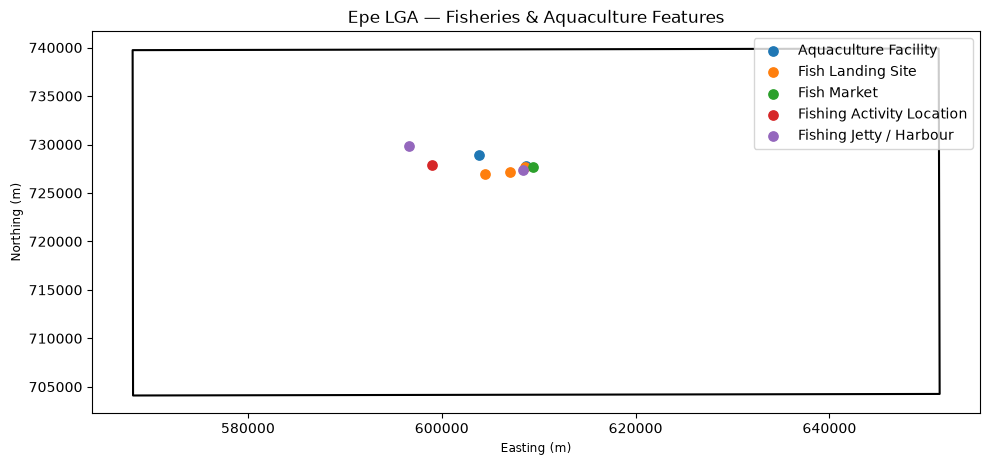

In [39]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))

# Epe boundary
epe_utm = epe_bbox

# Convert bbox to GeoDataFrame in UTM
epe_boundary = gpd.GeoDataFrame(
    {"name": ["Epe LGA"]},
    geometry=[epe_utm],
    crs="EPSG:4326"
).to_crs("EPSG:32631")

# Plot boundary
epe_boundary.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=1.5
)

# Plot fisheries/aquaculture
fisheries_utm.plot(
    ax=ax,
    markersize=45,
    column="category",
    legend=True
)

ax.set_title("Epe LGA — Fisheries & Aquaculture Features")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")

plt.tight_layout()
plt.show()

In [40]:
import pandas as pd

fisheries_candidates = [
    {
        "name": "Oluwo Fish Market",
        "category": "Fish Market",
        "evidence_tier": "Tier 1: Documented / Authoritative",
        "source": "Lagos State Government; PUNCH; Nigerian Tribune",
        "coordinate_status": "Existing coordinate",
        "notes": "Major fish trading location on the lagoon waterfront."
    },
    {
        "name": "Chief Market Fish Landing Station",
        "category": "Fish Landing Site",
        "evidence_tier": "Tier 1: Published Research",
        "source": "Scientific literature on fish fauna of Epe Lagoon",
        "coordinate_status": "Needs verification",
        "notes": "Documented landing station used by local fishermen."
    },
    {
        "name": "Epe Fish Collecting Center",
        "category": "Fish Landing / Collection Center",
        "evidence_tier": "Tier 2: Historical / Secondary",
        "source": "FAO fisheries documentation",
        "coordinate_status": "Needs verification",
        "notes": "Historical fish collection/distribution center."
    },
    {
        "name": "Ejinrin Fisheries / Waterfront Area",
        "category": "Fishing Activity Location",
        "evidence_tier": "Tier 2: Secondary / Mapped",
        "source": "Epe planning map and existing spatial inventory",
        "coordinate_status": "Existing coordinate",
        "notes": "Waterfront area associated with fishing and boat access."
    },
    {
        "name": "Ebute Oluwo Landing Point",
        "category": "Fish Landing Site",
        "evidence_tier": "Tier 2: Field / Secondary",
        "source": "Existing project inventory",
        "coordinate_status": "Existing coordinate",
        "notes": "Retain pending stronger source verification."
    },
    {
        "name": "Ebute Erepoto Landing Site",
        "category": "Fish Landing Site",
        "evidence_tier": "Tier 2: Field / Secondary",
        "source": "Existing project inventory",
        "coordinate_status": "Existing coordinate",
        "notes": "Retain pending stronger source verification."
    },
    {
        "name": "Ebute Berger Landing Site",
        "category": "Fish Landing Site",
        "evidence_tier": "Tier 2: Field / Secondary",
        "source": "Existing project inventory",
        "coordinate_status": "Existing coordinate",
        "notes": "Retain pending stronger source verification."
    },
    {
        "name": "Ebute Afuye Landing Point",
        "category": "Fishing Activity Location",
        "evidence_tier": "Tier 2: Field / Secondary",
        "source": "Existing project inventory",
        "coordinate_status": "Existing coordinate",
        "notes": "Retain pending stronger source verification."
    },
    {
        "name": "Epe Marina Waterfront & Jetty",
        "category": "Fishing Jetty / Harbour",
        "evidence_tier": "Tier 2: Secondary / Mapped",
        "source": "Existing project inventory",
        "coordinate_status": "Existing coordinate",
        "notes": "Relevant for fisheries access and waterfront activity."
    },
    {
        "name": "Ejinrin Lagoon Waterfront & Jetty",
        "category": "Fishing Jetty / Harbour",
        "evidence_tier": "Tier 2: Secondary / Mapped",
        "source": "Existing project inventory",
        "coordinate_status": "Existing coordinate",
        "notes": "Relevant for fisheries access and waterfront activity."
    },
    {
        "name": "Shaldag Aquaculture Farm",
        "category": "Aquaculture Facility",
        "evidence_tier": "Tier 2: Secondary / Mapped",
        "source": "Existing mapped inventory",
        "coordinate_status": "Existing coordinate",
        "notes": "Retain pending facility-level verification."
    },
    {
        "name": "Ketu-Ereyun Aquaculture Farm Estate",
        "category": "Aquaculture Facility",
        "evidence_tier": "Tier 2: Planned / Secondary",
        "source": "Existing project inventory",
        "coordinate_status": "Existing approximate coordinate",
        "notes": "Treat as planned/secondary evidence, not confirmed operational facility."
    },
]

fisheries_candidates_df = pd.DataFrame(fisheries_candidates)

fisheries_candidates_df

,name,category,evidence_tier,source,coordinate_status,notes
0,Oluwo Fish Market,Fish Market,Tier 1: Documented / Authoritative,Lagos State Government; PUNCH; Nigerian Tribune,Existing coordinate,Major fish trading location on the lagoon wate...
1,Chief Market Fish Landing Station,Fish Landing Site,Tier 1: Published Research,Scientific literature on fish fauna of Epe Lagoon,Needs verification,Documented landing station used by local fishe...
2,Epe Fish Collecting Center,Fish Landing / Collection Center,Tier 2: Historical / Secondary,FAO fisheries documentation,Needs verification,Historical fish collection/distribution center.
3,Ejinrin Fisheries / Waterfront Area,Fishing Activity Location,Tier 2: Secondary / Mapped,Epe planning map and existing spatial inventory,Existing coordinate,Waterfront area associated with fishing and bo...
4,Ebute Oluwo Landing Point,Fish Landing Site,Tier 2: Field / Secondary,Existing project inventory,Existing coordinate,Retain pending stronger source verification.
5,Ebute Erepoto Landing Site,Fish Landing Site,Tier 2: Field / Secondary,Existing project inventory,Existing coordinate,Retain pending stronger source verification.
6,Ebute Berger Landing Site,Fish Landing Site,Tier 2: Field / Secondary,Existing project inventory,Existing coordinate,Retain pending stronger source verification.
7,Ebute Afuye Landing Point,Fishing Activity Location,Tier 2: Field / Secondary,Existing project inventory,Existing coordinate,Retain pending stronger source verification.
8,Epe Marina Waterfront & Jetty,Fishing Jetty / Harbour,Tier 2: Secondary / Mapped,Existing project inventory,Existing coordinate,Relevant for fisheries access and waterfront a...
9,Ejinrin Lagoon Waterfront & Jetty,Fishing Jetty / Harbour,Tier 2: Secondary / Mapped,Existing project inventory,Existing coordinate,Relevant for fisheries access and waterfront a...


In [41]:
print("Total candidate fisheries/aquaculture records:",
      len(fisheries_candidates_df))

print("\nBy category:")
print(fisheries_candidates_df["category"].value_counts())

print("\nBy evidence tier:")
print(fisheries_candidates_df["evidence_tier"].value_counts())

Total candidate fisheries/aquaculture records: 12

By category:
category
Fish Landing Site                   4
Fishing Activity Location           2
Fishing Jetty / Harbour             2
Aquaculture Facility                2
Fish Market                         1
Fish Landing / Collection Center    1
Name: count, dtype: int64

By evidence tier:
evidence_tier
Tier 2: Secondary / Mapped            4
Tier 2: Field / Secondary             4
Tier 1: Documented / Authoritative    1
Tier 1: Published Research            1
Tier 2: Historical / Secondary        1
Tier 2: Planned / Secondary           1
Name: count, dtype: int64


In [42]:
# Add verification status based on evidence and coordinate availability

def verification_status(row):
    if row["coordinate_status"] == "Existing coordinate":
        if row["evidence_tier"].startswith("Tier 1"):
            return "Documented + coordinate available"
        else:
            return "Mapped/secondary + coordinate available"
    elif row["coordinate_status"] == "Existing approximate coordinate":
        return "Approximate location — verify before analysis"
    else:
        return "Documented location — coordinate needed"

fisheries_candidates_df["verification_status"] = (
    fisheries_candidates_df.apply(verification_status, axis=1)
)

# Add a geometry-ready flag
fisheries_candidates_df["geometry_ready"] = (
    fisheries_candidates_df["coordinate_status"]
    .isin(["Existing coordinate"])
)

# Display the important fields
fisheries_candidates_df[
    [
        "name",
        "category",
        "evidence_tier",
        "coordinate_status",
        "verification_status",
        "geometry_ready"
    ]
]

,name,category,evidence_tier,coordinate_status,verification_status,geometry_ready
0,Oluwo Fish Market,Fish Market,Tier 1: Documented / Authoritative,Existing coordinate,Documented + coordinate available,True
1,Chief Market Fish Landing Station,Fish Landing Site,Tier 1: Published Research,Needs verification,Documented location — coordinate needed,False
2,Epe Fish Collecting Center,Fish Landing / Collection Center,Tier 2: Historical / Secondary,Needs verification,Documented location — coordinate needed,False
3,Ejinrin Fisheries / Waterfront Area,Fishing Activity Location,Tier 2: Secondary / Mapped,Existing coordinate,Mapped/secondary + coordinate available,True
4,Ebute Oluwo Landing Point,Fish Landing Site,Tier 2: Field / Secondary,Existing coordinate,Mapped/secondary + coordinate available,True
5,Ebute Erepoto Landing Site,Fish Landing Site,Tier 2: Field / Secondary,Existing coordinate,Mapped/secondary + coordinate available,True
6,Ebute Berger Landing Site,Fish Landing Site,Tier 2: Field / Secondary,Existing coordinate,Mapped/secondary + coordinate available,True
7,Ebute Afuye Landing Point,Fishing Activity Location,Tier 2: Field / Secondary,Existing coordinate,Mapped/secondary + coordinate available,True
8,Epe Marina Waterfront & Jetty,Fishing Jetty / Harbour,Tier 2: Secondary / Mapped,Existing coordinate,Mapped/secondary + coordinate available,True
9,Ejinrin Lagoon Waterfront & Jetty,Fishing Jetty / Harbour,Tier 2: Secondary / Mapped,Existing coordinate,Mapped/secondary + coordinate available,True


In [43]:
# Save the candidate inventory as CSV

fisheries_candidates_df.to_csv(
    "data/processed/epe_fisheries_aquaculture_candidate_inventory.csv",
    index=False
)

print("Saved:")
print("data/processed/epe_fisheries_aquaculture_candidate_inventory.csv")

Saved:
data/processed/epe_fisheries_aquaculture_candidate_inventory.csv


In [44]:
# Quick verification summary

print("Total records:", len(fisheries_candidates_df))
print(
    "Geometry-ready:",
    fisheries_candidates_df["geometry_ready"].sum()
)
print(
    "Coordinates still needed:",
    (~fisheries_candidates_df["geometry_ready"]).sum()
)
print(
    "\nVerification status:"
)
print(
    fisheries_candidates_df["verification_status"].value_counts()
)

Total records: 12
Geometry-ready: 9
Coordinates still needed: 3

Verification status:
verification_status
Mapped/secondary + coordinate available          8
Documented location — coordinate needed          2
Documented + coordinate available                1
Approximate location — verify before analysis    1
Name: count, dtype: int64
